In [2]:
import os
import time
from pathlib import Path

import numpy as np

import eicvibe.notebook as ev

MACHINE = Path(os.environ.get("EICVIBE_MACHINE", "../../virtual_accelerator/EIN/machine"))
RUNS = Path(os.environ.get("EICVIBE_RUNS", "runs"))  # each run writes a folder here
ENGINE = "trackpad" if ev.engine("trackpad").available() else "xsuite"
PARTICLES = 200
m = ev.machine(MACHINE)
m

Machine ein
  folder   ../../virtual_accelerator/EIN/machine
  routes   direct, bar
  devices  855, 2,280 channels
  branch    kind  length (m)  elements  BPMs  energy (GeV)  ramp  beam                    
  ltr       line  63.684      61        15    0.75          –     19,998 particles, 1.7 nC
  itl       line  11.176      19        4     0.75          –     –                       
  bar       ring  36.521      51        10    0.75          –     –                       
  etl       line  11.176      19        4     0.75          –     –                       
  rcs       ring  1506.93     917       192   0.75          rcs   –                       
  rte       line  126.91      51        0     10            –     –                       
  prj       line  76.765      126       23    0.000831369   –     –                       
  prj_gun   line  1.601       9         1     0.000831369   –     –                       
  prj_spin  line  3.15        8         1     0.000831369   –     –

## The BAR

Select the branch: its row of the machine's table gives its kind, length, elements, BPMs and energy.

In [3]:
BRANCH = "bar"
ev.table(m).loc[[BRANCH]]

,kind,length (m),elements,BPMs,energy (GeV),ramp,beam
branch,,,,,,,
bar,ring,36.521,51,10,0.75,NaN,NaN


## Its optics

A ring's optics are its periodic solution, computed by the engine in a worker process of its own
(TrackPad's first use starts Julia, about half a minute). The summary gives the tunes, the
chromaticity and the momentum compaction; the plot, beta and dispersion under the ring's elements.

In [4]:
optics = ev.optics(m, BRANCH, engine=ENGINE)
optics

Optics of bar (ring)
  engine               trackpad standard: TPSA
  tunes                2.42141, 1.47466
  chromaticity         -0.06127, -0.08478
  momentum compaction  0.079376
  at                   101 occurrences, 36.5206 m; 782 points inside them
              x: min … max     y             
  beta        0.5316 … 16.19   0.8509 … 10.74
  alpha       -6.594 … 6.594   -4.593 … 4.593
  eta         0.01066 … 1.378  0 … 0         
  orbit (mm)  0 … 0            0 … 0

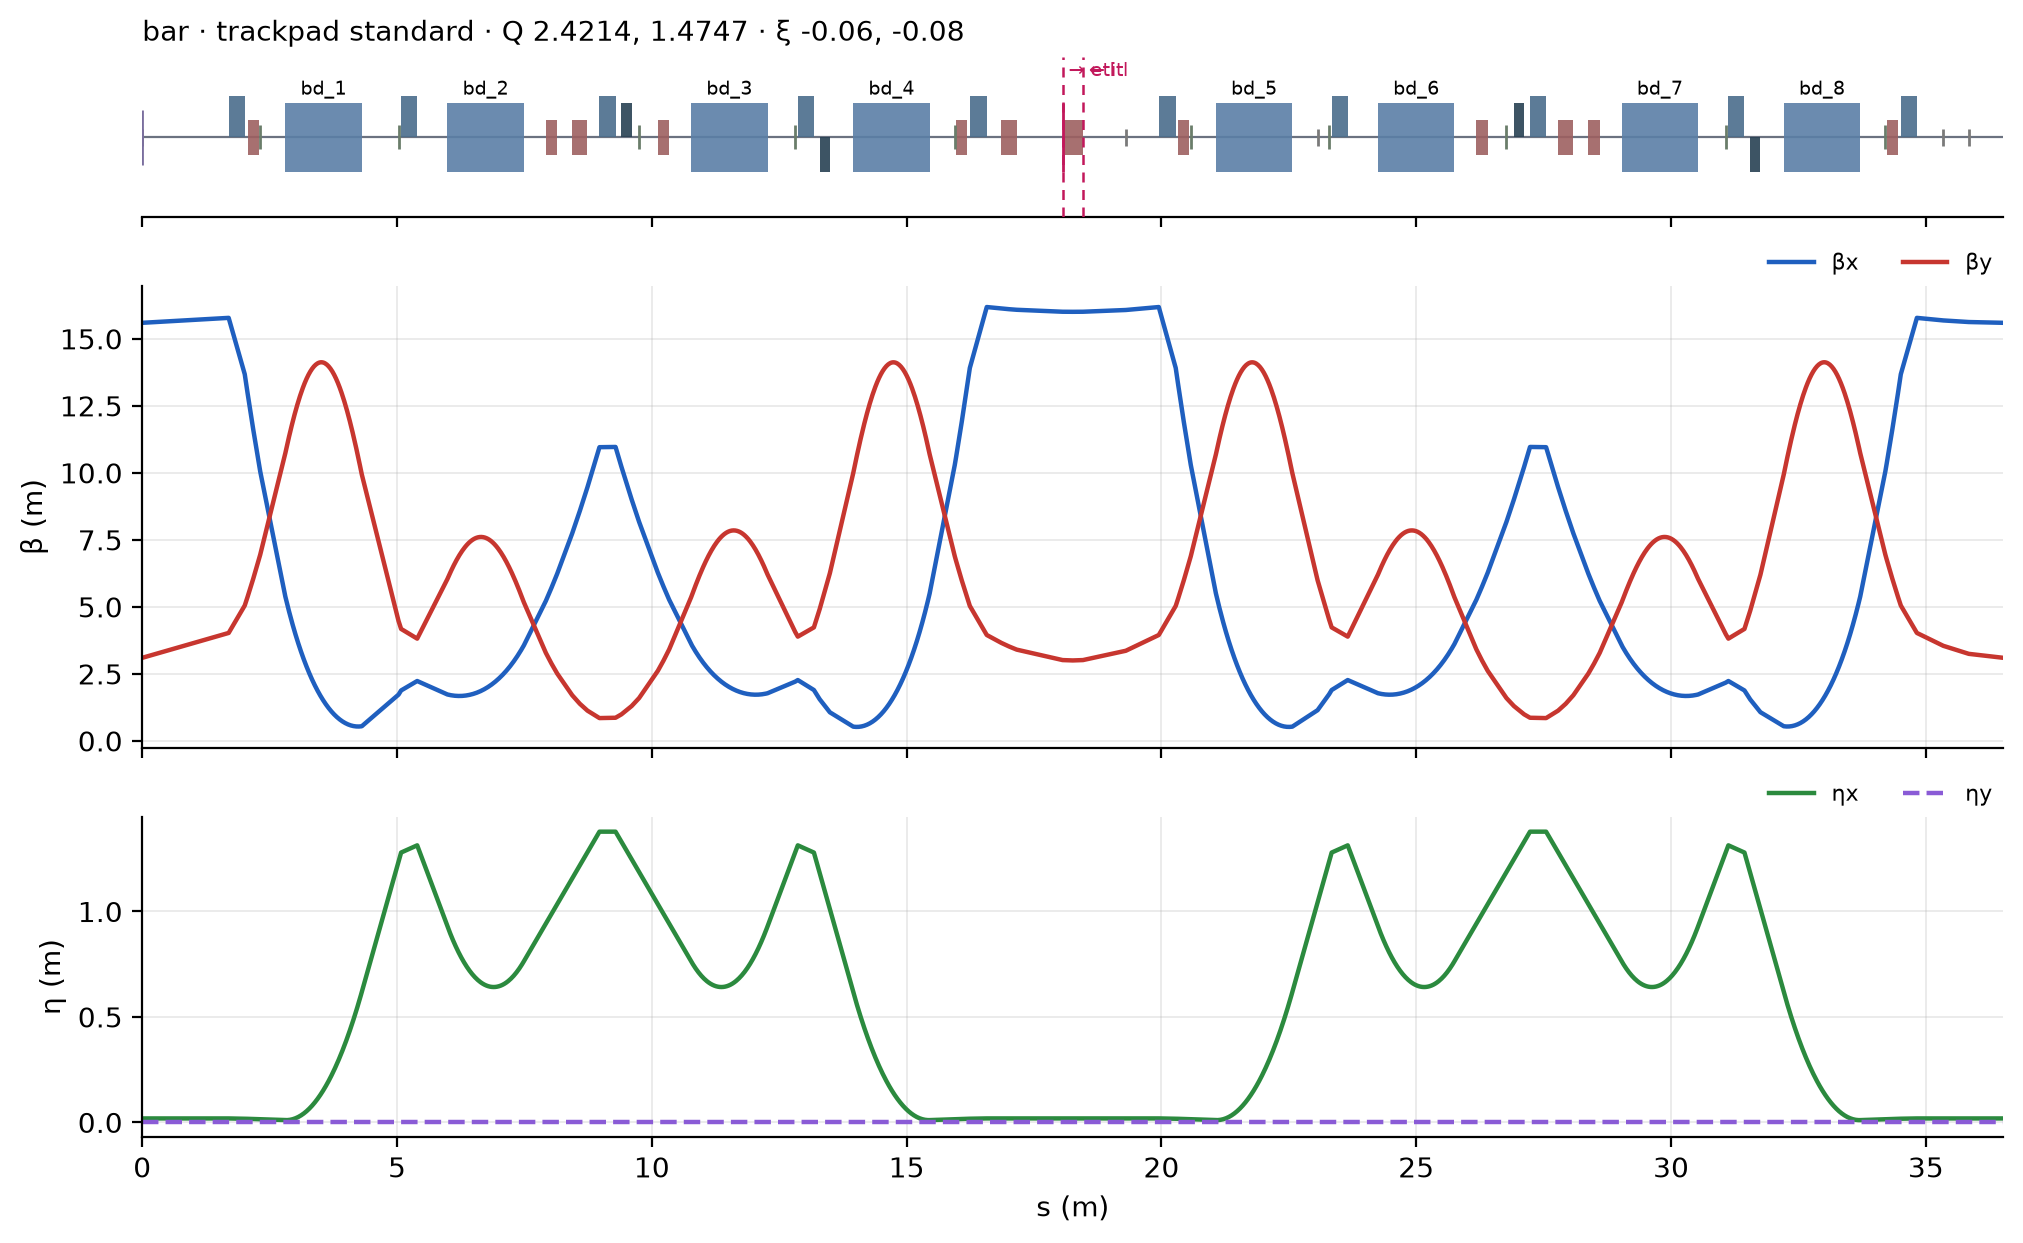

In [5]:
ev.plot_optics(optics, m)

## The injection point

The ITL's beam lands in the BAR at the exit of its septum: the fork from the ITL into the BAR says
where. The optics there are the ring's periodic optics, computed above.

In [6]:
[fork] = m.lattice.forks_into(BRANCH)  # the ITL's
INJECTION = fork.to_occurrence  # the beam lands at its exit
print(f"injection at the exit of {m.lattice.placement(INJECTION).name}, s = {fork.s_to:.4f} m")
ev.table(optics, m).loc[[INJECTION]]

injection at the exit of septum, s = 18.4603 m


,name,kind,s,beta_x,alpha_x,beta_y,alpha_y,mu_x,mu_y,eta_x,etap_x,eta_y,etap_y,x,px,y,py
occurrence,,,,,,,,,,,,,,,,,
occ_8fadc09ce510793b,septum,Kicker,18.460314,16.009856,-0.012494,3.015046,-0.066628,1.212693,0.747917,0.018689,-2.521050e-15,0.0,0.0,0.0,0.0,0.0,0.0


## The ring with radiation on

At 0.75 GeV the BAR's electrons radiate about 15 keV a turn. Three things make a bunch fit the ring
then:

- **The RF on its stable side.** The machine files give the BAR's cavity phase 0, the unstable side
  for electrons above transition (ADR 0007); a stored beam needs π.
- **The closed orbit with radiation.** The bunch loses energy every turn and sits where the RF gives it
  back, a few centimetres ahead in zeta.
- **Its length.** The bunch length that goes with a momentum spread in the RF bucket comes from the
  ring's 6D one-turn map (`ring_matching`), which also gives the synchrotron tune.

The same one-turn map gives the damping times: with radiation its eigenvalues lie inside the unit
circle, |λ| = exp(−1/τ), τ the turns in which an amplitude damps by e. Matching uses the mean radiation
only (quantum excitation, being random, has no closed orbit); tracking has both.

In [7]:
import pandas as pd

from eicvibe.domain.lattice import ElementKind
from eicvibe.virtual import one_turn_matrix, ring_matching, twiss_bunch

[cavity] = [o for o in optics.occurrences if m.lattice.placement(o).kind is ElementKind.RFCAVITY]
RF = {(cavity, "RFP.phase"): np.pi}  # the stable side for electrons above transition
MATCHING = ev.Options(effects={ev.Effect.LONGITUDINAL, ev.Effect.RADIATION_DAMPING})
RADIATION = ev.Options(effects=MATCHING.effects | {ev.Effect.QUANTUM_EXCITATION})
PERIOD = optics.s[-1] / 299_792_458  # s a turn (β = 1 to 2e-7)

with ev.session(m, BRANCH, engine=ENGINE, values=RF) as s:
    orbit = s.orbit(ev.OrbitRequest(options=MATCHING))
    closed = np.column_stack([orbit.x, orbit.px, orbit.y, orbit.py, orbit.zeta, orbit.delta])  # at each exit
    ring = ring_matching(s, closed[-1], MATCHING, "the BAR's start")
    one_turn = one_turn_matrix(s, closed[-1], MATCHING)

values, vectors = np.linalg.eig(one_turn)
modes = {}
for value, vector in zip(values, vectors.T, strict=True):
    if value.imag > 0:  # one of each pair
        plane = "xyz"[np.argmax([np.linalg.norm(vector[k : k + 2]) for k in (0, 2, 4)])]
        tau = -1 / np.log(abs(value))
        modes[plane] = {"tune": np.angle(value) / (2 * np.pi), "damping time (turns)": tau,
                        "damping time (ms)": tau * PERIOD * 1e3}
DAMPING = {plane: mode["damping time (turns)"] for plane, mode in modes.items()}
pd.DataFrame(modes).T.sort_index()

,tune,damping time (turns),damping time (ms)
x,0.421414,60410.794993,7.359225
y,0.474638,102349.871440,12.468231
z,0.004473,78282.082931,9.536300


## A beam matched at the injection point

The bunch is a Gaussian matched to the optics at the injection point (beta, alpha and dispersion
there) and centred on the closed orbit there, with the emittances and momentum spread of the beam the
preinjector delivers (`beams/ltr`) and the length the RF matches to that spread.

In [8]:
def moments(c: np.ndarray) -> dict[str, float]:
    """A bunch's rms emittances (m rad, its dispersion taken out), momentum spread and length (m)."""
    c = c - c.mean(axis=0)
    delta = c[:, 5]
    out = {}
    for plane, k in (("x", 0), ("y", 2)):
        pair = c[:, k : k + 2] - np.outer(delta, delta @ c[:, k : k + 2]) / (delta @ delta)
        out[f"emittance_{plane}"] = float(np.sqrt(np.linalg.det(np.cov(pair.T))))
    return out | {"sigma_delta": float(delta.std()), "sigma_zeta": float(c[:, 4].std())}


delivered = moments(m.beams["ltr"].particles)
beam = ev.Beam(
    particles=PARTICLES,
    emittance_x=delivered["emittance_x"],
    emittance_y=delivered["emittance_y"],
    sigma_delta=delivered["sigma_delta"],
    charge=m.beams["ltr"].charge,
)
beam = ev.Beam(**(beam.model_dump() | {"sigma_zeta": ring.sigma_zeta(beam)}))  # its length matched to the RF
centre = closed[orbit.occurrences.index(INJECTION)]
bunch = twiss_bunch(np.random.default_rng(beam.seed), beam, optics.at(INJECTION), centre)
print(f"closed orbit at injection: zeta {centre[4] * 1e3:.1f} mm, delta {centre[5]:.2g}; "
      f"synchrotron tune {ring.summary(beam)['synchrotron_tune']:.5f}")
pd.DataFrame({"beam": beam.model_dump(include=set(delivered)), "bunch": moments(bunch)}).T

closed orbit at injection: zeta 71.2 mm, delta -1.5e-08; synchrotron tune 0.00447


,emittance_x,emittance_y,sigma_delta,sigma_zeta
beam,4.939298e-08,3.166965e-08,0.002294,0.236600
bunch,4.051891e-08,3.476518e-08,0.002285,0.244559


## Tracking with radiation

From the septum the bunch goes once to the ring's start (half a turn), then turn after turn; every
`EVERY` turns its moments are taken. With TrackPad and 200 particles the 60,000 turns below (7 ms)
take about three minutes; Xsuite takes much longer.

In [9]:
TURNS, EVERY = 60_000, 500

occurrences = list(optics.occurrences)
after = occurrences[occurrences.index(INJECTION) + 1]
rows = [{"turn": 0, "particles": len(bunch), **moments(bunch)}]
with ev.session(m, BRANCH, engine=ENGINE, values=RF) as s:
    track = s.track_beam(bunch, 1, (), RADIATION, start=after)  # the septum to the ring's start
    coordinates = np.asarray(track.final)[~np.asarray(track.lost)]
    for turn in range(EVERY, TURNS + 1, EVERY):
        track = s.track_beam(coordinates, EVERY, (), RADIATION)
        coordinates = np.asarray(track.final)[~np.asarray(track.lost)]
        rows.append({"turn": turn, "particles": len(coordinates), **moments(coordinates)})
history = pd.DataFrame(rows).set_index("turn")
history.iloc[[0, len(history) // 2, -1]]

,particles,emittance_x,emittance_y,sigma_delta,sigma_zeta
turn,,,,,
0,200,4.051891e-08,3.476518e-08,0.002285,0.244559
30000,199,9.000049e-08,1.933530e-08,0.001529,0.177913
60000,199,1.231242e-07,1.079493e-08,0.001143,0.129050


Radiation damps the oscillations and quantum excitation feeds them, so each second moment relaxes to
its equilibrium with half the amplitudes' damping time: m(t) = m_eq + (m_0 − m_eq) exp(−2t/τ). With τ
from the one-turn map, the equilibria follow from the tracked moments (a least-squares fit of m_eq
alone). The dashed lines are those relaxations; the vertical equilibrium is near zero, as the ring has
no vertical dispersion or coupling.

In [ ]:
from IPython.display import display

turn = history.index.to_numpy(float)
ms = turn * PERIOD * 1e3
equilibria = {}
for plane, moment, scale, label in (
    ("x", history.emittance_x, 1e9, "εx (nm)"),
    ("y", history.emittance_y, 1e9, "εy (nm)"),
    ("z", history.sigma_delta**2, 1e6, "σδ² (10⁻⁶)"),
):
    f = np.exp(-2 * turn / DAMPING[plane])
    start = moment.iloc[0]
    equilibrium = ((moment - start * f) * (1 - f)).sum() / ((1 - f) ** 2).sum()
    equilibria[plane] = equilibrium
    relaxation = equilibrium + (start - equilibrium) * f
    display(ev.chart([{"label": "tracked", "x": ms, "y": moment * scale, "style": "points"},
                      {"label": "relaxation", "x": ms, "y": relaxation * scale, "dash": [6, 3]}],
                     title=f"{label.split()[0]} with radiation", x_label="time after injection (ms)",
                     y_label=label, height=200))
pd.DataFrame({"equilibrium": {"εx (nm)": equilibria["x"] * 1e9, "εy (nm)": equilibria["y"] * 1e9,
                              "σδ (10⁻³)": np.sqrt(max(equilibria["z"], 0.0)) * 1e3}})